<a href="https://colab.research.google.com/github/kaufai/PTB-XL-ECG-Classification-Project/blob/main/ptb_xl_dataset_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PTB-XL ECG superclass classification: SVM vs 1D-CNN vs CNN-GRU

Multi-label classification of 12-lead ECGs (100 Hz) into five diagnostic superclasses (CD, HYP, MI, NORM, STTC) on the public [PTB-XL dataset](https://physionet.org/content/ptb-xl/1.0.3/), using the recommended patient-level folds (train: 1-8, validation: 9, test: 10).

**How to run:** Runtime > Change runtime type > **T4 GPU**, then Runtime > **Run all**. Expect roughly 15-30 minutes on a T4 (the download, data loading and SVM run on CPU; the two neural networks run on the GPU).

**Outputs** (saved in `results/` and downloaded as `results.zip` at the end): `results.csv`, `results_per_class.csv`, `training_log.csv`, `confusion_matrices_cnn_gru.png`, `requirements.txt`.

In [ ]:
!pip install -q wfdb

## 1. Setup, configuration and seeds

In [ ]:
import os, random, copy, ast, shutil, subprocess
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import scipy.signal
import scipy.stats
import wfdb
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, roc_auc_score, classification_report,
                             multilabel_confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
EPOCHS = 10
BATCH_SIZE = 64
THRESHOLD = 0.5            # fixed decision threshold for the neural networks (not tuned on the test fold)
TARGET_CLASSES = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
DATA_URL = ('https://physionet.org/static/published-projects/ptb-xl/'
            'ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip')
DATA_PATH = 'ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'
OUT_DIR = 'results'
os.makedirs(OUT_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gen = torch.Generator()    # controls the DataLoader shuffling order


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    gen.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()
print('Device:', device, '| torch', torch.__version__)
if device.type == 'cpu':
    print('WARNING: no GPU found. Training will take hours. '
          'Use Runtime > Change runtime type > T4 GPU, then run all again.')

Device: cuda | torch 2.11.0+cu130


## 2. Download PTB-XL and load metadata

The download is about 1.7 GB and is skipped if the folder already exists.

In [ ]:
if not os.path.exists(DATA_PATH):
    subprocess.run(['wget', '-q', '-O', 'ptb-xl.zip', DATA_URL], check=True)
    subprocess.run(['unzip', '-q', 'ptb-xl.zip'], check=True)
    os.remove('ptb-xl.zip')

df_meta = pd.read_csv(os.path.join(DATA_PATH, 'ptbxl_database.csv'), index_col='ecg_id')
df_meta['scp_codes'] = df_meta['scp_codes'].apply(ast.literal_eval)
scp = pd.read_csv(os.path.join(DATA_PATH, 'scp_statements.csv'), index_col=0)
print(f'{len(df_meta)} records from {df_meta.patient_id.nunique()} patients')

21799 records from 18869 patients


## 3. Load the 100 Hz waveforms and filter them

Band-pass filter: 0.5-49.9 Hz, 4th-order Butterworth, applied forwards and backwards (zero phase). The upper edge is kept just below the 50 Hz Nyquist frequency.

In [ ]:
def load_signals(df, path):
    X = np.empty((len(df), 1000, 12), dtype=np.float32)
    for i, name in enumerate(df.filename_lr):
        X[i] = wfdb.rdsamp(os.path.join(path, name))[0]
        if (i + 1) % 5000 == 0:
            print(f'  loaded {i + 1}/{len(df)} records')
    return X


def bandpass(X, low=0.5, high=49.9, fs=100.0, order=4, chunk=2000):
    sos = scipy.signal.butter(order, [low, high], btype='band', fs=fs, output='sos')
    out = np.empty_like(X)
    for i in range(0, len(X), chunk):
        out[i:i + chunk] = scipy.signal.sosfiltfilt(sos, X[i:i + chunk], axis=1)
    return out


print('Loading 100 Hz waveforms (about 2-3 minutes)...')
X = load_signals(df_meta, DATA_PATH)
print('Records containing NaN values:', int(np.isnan(X).any(axis=(1, 2)).sum()))
X = np.nan_to_num(X, nan=0.0)      # NaNs must be removed before filtering, or they spread over the whole record
X = bandpass(X)
print('Waveform array:', X.shape)

Loading 100 Hz waveforms (about 2-3 minutes)...
  loaded 5000/21799 records
  loaded 10000/21799 records
  loaded 15000/21799 records
  loaded 20000/21799 records
Records containing NaN values: 0
Waveform array: (21799, 1000, 12)


## 4. Labels and patient-level splits

A superclass is positive for a record if any SCP statement belonging to it has likelihood >= 50. Records with no superclass label are dropped. Splits follow the dataset's `strat_fold` column.

In [ ]:
def superclass_labels(df, scp_statements, classes=TARGET_CLASSES, min_likelihood=50):
    code_to_class = {c: row['diagnostic_class'] for c, row in scp_statements.iterrows()
                     if pd.notna(row['diagnostic_class']) and row['diagnostic_class'] in classes}
    y = np.zeros((len(df), len(classes)), dtype=np.float32)
    for i, codes in enumerate(df['scp_codes']):
        for code, likelihood in codes.items():
            if code in code_to_class and likelihood >= min_likelihood:
                y[i, classes.index(code_to_class[code])] = 1.0
    return y


Y = superclass_labels(df_meta, scp)
labeled = Y.sum(axis=1) > 0
print(f'Records with at least one superclass label: {labeled.sum()} of {len(labeled)} (the rest are dropped)')

fold = df_meta['strat_fold'].values
masks = {'train': labeled & (fold <= 8),
         'val':   labeled & (fold == 9),
         'test':  labeled & (fold == 10)}

X_tr, y_tr = X[masks['train']], Y[masks['train']]
X_va, y_va = X[masks['val']],   Y[masks['val']]
X_te, y_te = X[masks['test']],  Y[masks['test']]
del X

for split, (xs, ys) in {'train': (X_tr, y_tr), 'val': (X_va, y_va), 'test': (X_te, y_te)}.items():
    print(f'{split:5s}: {xs.shape[0]:5d} records | positives per class:',
          dict(zip(TARGET_CLASSES, ys.sum(axis=0).astype(int))))

pid = df_meta['patient_id'].values
shared = set(pid[masks['train']]) & set(pid[masks['test']])
print('Patients shared between train and test folds:', len(shared))

Records with at least one superclass label: 20373 of 21799 (the rest are dropped)
train: 16289 records | positives per class: {'CD': np.int64(3900), 'HYP': np.int64(1820), 'MI': np.int64(3307), 'NORM': np.int64(7542), 'STTC': np.int64(4062)}
val  :  2034 records | positives per class: {'CD': np.int64(495), 'HYP': np.int64(216), 'MI': np.int64(412), 'NORM': np.int64(942), 'STTC': np.int64(510)}
test :  2050 records | positives per class: {'CD': np.int64(496), 'HYP': np.int64(222), 'MI': np.int64(415), 'NORM': np.int64(954), 'STTC': np.int64(506)}
Patients shared between train and test folds: 0


## 5. Evaluation helper

Reports micro/macro F1 and macro AUC on the held-out test fold (fold 10), plus per-class scores. The SVM uses its decision function (threshold 0); the neural networks use sigmoid probabilities (threshold 0.5).

In [ ]:
all_summary, all_per_class = [], []


def report(name, y_true, scores, thr=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    pred = (scores >= thr).astype(int)
    f1_c = f1_score(y_true, pred, average=None, zero_division=0)
    auc_c = roc_auc_score(y_true, scores, average=None)
    print(f'\n=== {name} (test fold 10) ===')
    print(classification_report(y_true, pred, target_names=TARGET_CLASSES, zero_division=0))
    summary = {'model': name,
               'micro_f1': f1_score(y_true, pred, average='micro', zero_division=0),
               'macro_f1': f1_c.mean(),
               'macro_auc': auc_c.mean()}
    print({k: round(float(v), 4) for k, v in summary.items() if k != 'model'})
    all_summary.append(summary)
    for c, f, a in zip(TARGET_CLASSES, f1_c, auc_c):
        all_per_class.append({'model': name, 'class': c, 'f1': f, 'auc': a})

## 6. Baseline: SVM on 48 handcrafted features

Per lead: mean, variance, skewness and mean spectral energy (4 features x 12 leads). Missing values are imputed and features standardised, both fitted on the training set only.

In [ ]:
def extract_features(X, batch=2000):
    feats = []
    for i in range(0, len(X), batch):
        b = X[i:i + batch].astype(np.float64)                         # (n, 1000, 12)
        mean = b.mean(axis=1)
        var = b.var(axis=1)
        skew = scipy.stats.skew(b, axis=1)
        energy = (np.abs(np.fft.rfft(b, axis=1)) ** 2).mean(axis=1)   # mean spectral energy
        feats.append(np.stack([mean, var, skew, energy], axis=2).reshape(len(b), -1))
    return np.vstack(feats)                                           # (n, 48)


F_tr, F_te = extract_features(X_tr), extract_features(X_te)
imputer, scaler = SimpleImputer(strategy='mean'), StandardScaler()
F_tr = scaler.fit_transform(imputer.fit_transform(F_tr))
F_te = scaler.transform(imputer.transform(F_te))
print('Feature matrix:', F_tr.shape)

svm = OneVsRestClassifier(SVC(kernel='rbf', C=1.0, random_state=SEED), n_jobs=-1)
svm.fit(F_tr, y_tr.astype(int))
report('SVM (48 features)', y_te, svm.decision_function(F_te), thr=0.0)

Feature matrix: (16289, 48)

=== SVM (48 features) (test fold 10) ===
              precision    recall  f1-score   support

          CD       0.81      0.46      0.59       496
         HYP       0.77      0.27      0.39       222
          MI       0.63      0.19      0.30       415
        NORM       0.75      0.84      0.79       954
        STTC       0.78      0.24      0.37       506

   micro avg       0.75      0.50      0.60      2593
   macro avg       0.75      0.40      0.49      2593
weighted avg       0.75      0.50      0.56      2593
 samples avg       0.57      0.53      0.54      2593

{'micro_f1': 0.5985, 'macro_f1': 0.4869, 'macro_auc': 0.8246}


## 7. PyTorch datasets and data loaders

In [ ]:
class ECGDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).transpose(1, 2).contiguous()   # (N, 12 leads, 1000 samples)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_loader = DataLoader(ECGDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True, generator=gen)
val_loader = DataLoader(ECGDataset(X_va, y_va), batch_size=BATCH_SIZE)
test_loader = DataLoader(ECGDataset(X_te, y_te), batch_size=BATCH_SIZE)
print(len(train_loader), 'train batches,', len(val_loader), 'validation batches,', len(test_loader), 'test batches')

255 train batches, 32 validation batches, 33 test batches


## 8. Models

**1D-CNN:** four conv blocks (conv, batch norm, ReLU, max-pool) followed by global average pooling. **CNN-GRU:** a shallow CNN compresses 1000 time steps to 125, then a 2-layer bidirectional GRU with max-pooling over time.

In [ ]:
class ECGCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=15, padding=7), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=11, padding=5), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=7, padding=3), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(128, 256, kernel_size=5, padding=2), nn.BatchNorm1d(256), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.global_pool(self.features(x)).squeeze(-1)
        return self.classifier(x)


class ECGHybridModel(nn.Module):
    def __init__(self, num_classes=5, rnn_hidden=128):
        super().__init__()
        self.cnn_extractor = nn.Sequential(                      # (B, 12, 1000) -> (B, 128, 125)
            nn.Conv1d(12, 32, kernel_size=15, padding=7), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.rnn = nn.GRU(128, rnn_hidden, num_layers=2, batch_first=True,
                          bidirectional=True, dropout=0.2)
        self.classifier = nn.Linear(rnn_hidden * 2, num_classes)

    def forward(self, x):
        h = self.cnn_extractor(x).transpose(1, 2)                # (B, 125, 128)
        out, _ = self.rnn(h)                                     # (B, 125, 256)
        pooled, _ = torch.max(out, dim=1)                        # max over time
        return self.classifier(pooled)

## 9. Training

BCE-with-logits loss, AdamW (lr 1e-3, weight decay 1e-4), 10 epochs. The checkpoint with the lowest **validation** loss is kept, and the test fold is only used once per model at the end. Each model is trained after re-seeding for reproducibility.

In [ ]:
criterion = nn.BCEWithLogitsLoss()


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, probs, labels = 0.0, [], []
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * xb.size(0)
            probs.append(torch.sigmoid(logits).detach().cpu().numpy())
            labels.append(yb.cpu().numpy())
    return total / len(loader.dataset), np.vstack(probs), np.vstack(labels)


def fit(model, name, epochs=EPOCHS):
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    best_loss, best_state, history = float('inf'), None, []
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, optimizer)
        va_loss, va_p, va_y = run_epoch(model, val_loader)
        va_f1 = f1_score(va_y.astype(int), (va_p >= THRESHOLD).astype(int),
                         average='micro', zero_division=0)
        history.append({'model': name, 'epoch': epoch, 'train_loss': tr_loss,
                        'val_loss': va_loss, 'val_micro_f1': va_f1})
        print(f'{name} epoch {epoch}/{epochs} | train loss {tr_loss:.4f} | '
              f'val loss {va_loss:.4f} | val micro F1 {va_f1:.4f}')
        if va_loss < best_loss:
            best_loss, best_state = va_loss, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, history

In [ ]:
seed_everything()
cnn, hist_cnn = fit(ECGCNN().to(device), '1D-CNN')
_, p_cnn, y_cnn = run_epoch(cnn, test_loader)
report('1D-CNN', y_cnn, p_cnn)

1D-CNN epoch 1/10 | train loss 0.3047 | val loss 0.2940 | val micro F1 0.7504
1D-CNN epoch 2/10 | train loss 0.2634 | val loss 0.3159 | val micro F1 0.7200
1D-CNN epoch 3/10 | train loss 0.2510 | val loss 0.2687 | val micro F1 0.7701
1D-CNN epoch 4/10 | train loss 0.2422 | val loss 0.2768 | val micro F1 0.7672
1D-CNN epoch 5/10 | train loss 0.2342 | val loss 0.2563 | val micro F1 0.7780
1D-CNN epoch 6/10 | train loss 0.2286 | val loss 0.2753 | val micro F1 0.7641
1D-CNN epoch 7/10 | train loss 0.2235 | val loss 0.2588 | val micro F1 0.7809
1D-CNN epoch 8/10 | train loss 0.2215 | val loss 0.2516 | val micro F1 0.7852
1D-CNN epoch 9/10 | train loss 0.2145 | val loss 0.2544 | val micro F1 0.7891
1D-CNN epoch 10/10 | train loss 0.2114 | val loss 0.2518 | val micro F1 0.7857

=== 1D-CNN (test fold 10) ===
              precision    recall  f1-score   support

          CD       0.79      0.74      0.77       496
         HYP       0.76      0.40      0.52       222
          MI       0.82  

In [ ]:
seed_everything()
hybrid, hist_gru = fit(ECGHybridModel().to(device), 'CNN-GRU')
_, p_gru, y_gru = run_epoch(hybrid, test_loader)
report('CNN-GRU', y_gru, p_gru)

CNN-GRU epoch 1/10 | train loss 0.3313 | val loss 0.2916 | val micro F1 0.7614
CNN-GRU epoch 2/10 | train loss 0.2722 | val loss 0.2756 | val micro F1 0.7636
CNN-GRU epoch 3/10 | train loss 0.2541 | val loss 0.2751 | val micro F1 0.7680
CNN-GRU epoch 4/10 | train loss 0.2439 | val loss 0.2874 | val micro F1 0.7594
CNN-GRU epoch 5/10 | train loss 0.2343 | val loss 0.2621 | val micro F1 0.7711
CNN-GRU epoch 6/10 | train loss 0.2264 | val loss 0.2580 | val micro F1 0.7895
CNN-GRU epoch 7/10 | train loss 0.2215 | val loss 0.2546 | val micro F1 0.7912
CNN-GRU epoch 8/10 | train loss 0.2168 | val loss 0.2516 | val micro F1 0.7913
CNN-GRU epoch 9/10 | train loss 0.2088 | val loss 0.2511 | val micro F1 0.7918
CNN-GRU epoch 10/10 | train loss 0.2050 | val loss 0.2493 | val micro F1 0.7966

=== CNN-GRU (test fold 10) ===
              precision    recall  f1-score   support

          CD       0.82      0.70      0.76       496
         HYP       0.71      0.51      0.59       222
          MI  

## 10. Results, confusion matrices and saved files

In [ ]:
results = pd.DataFrame(all_summary).round(4)
per_class = pd.DataFrame(all_per_class).round(4)
training_log = pd.DataFrame(hist_cnn + hist_gru).round(4)

results.to_csv(f'{OUT_DIR}/results.csv', index=False)
per_class.to_csv(f'{OUT_DIR}/results_per_class.csv', index=False)
training_log.to_csv(f'{OUT_DIR}/training_log.csv', index=False)

display(results)
display(per_class.pivot(index='class', columns='model', values='f1').rename_axis(columns='F1'))
display(per_class.pivot(index='class', columns='model', values='auc').rename_axis(columns='AUC'))

try:
    print(results.to_markdown(index=False))      # paste this table into the README
except ImportError:
    print(results.to_string(index=False))

,model,micro_f1,macro_f1,macro_auc
0,SVM (48 features),0.5985,0.4869,0.8246
1,1D-CNN,0.7839,0.7226,0.9300
2,CNN-GRU,0.7821,0.7286,0.9304


F1,1D-CNN,CNN-GRU,SVM (48 features)
class,,,
CD,0.7659,0.7557,0.5887
HYP,0.5207,0.5916,0.3946
MI,0.6808,0.6450,0.2957
NORM,0.8821,0.8874,0.7893
STTC,0.7635,0.7634,0.3661


AUC,1D-CNN,CNN-GRU,SVM (48 features)
class,,,
CD,0.9213,0.9231,0.8015
HYP,0.9073,0.9004,0.8495
MI,0.9298,0.9288,0.8037
NORM,0.9566,0.9594,0.8698
STTC,0.9349,0.9403,0.7983


| model             |   micro_f1 |   macro_f1 |   macro_auc |
|:------------------|-----------:|-----------:|------------:|
| SVM (48 features) |     0.5985 |     0.4869 |      0.8246 |
| 1D-CNN            |     0.7839 |     0.7226 |      0.93   |
| CNN-GRU           |     0.7821 |     0.7286 |      0.9304 |


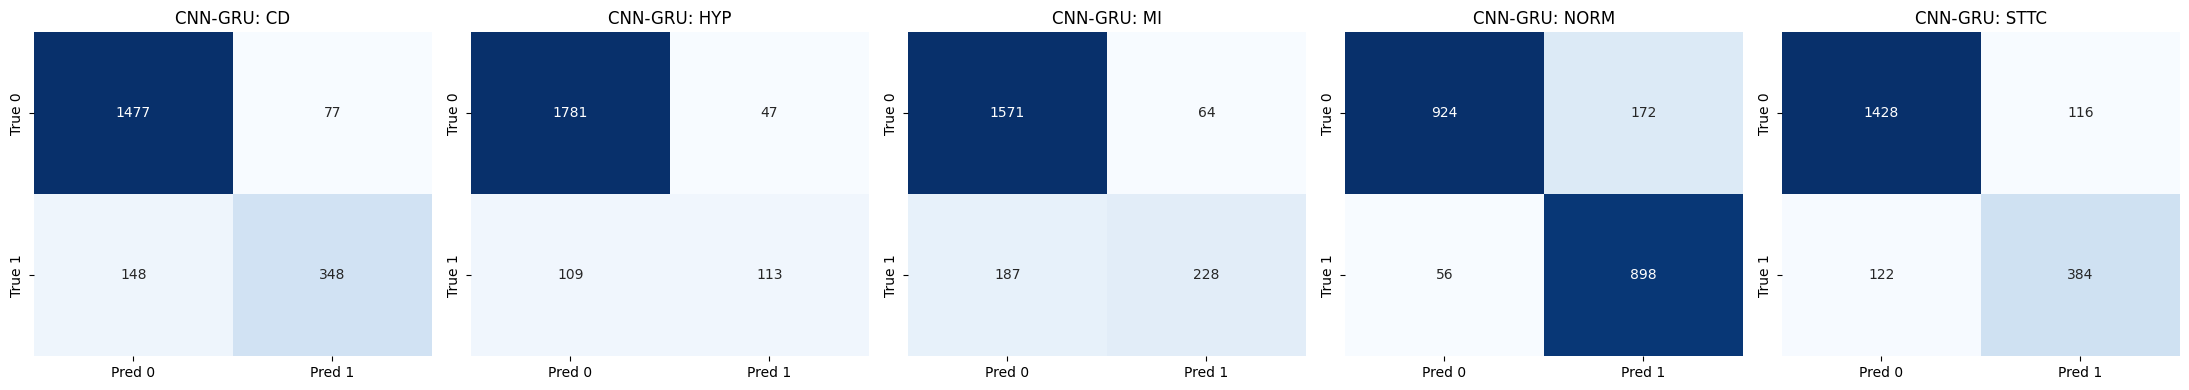

In [ ]:
mcm = multilabel_confusion_matrix(y_gru.astype(int), (p_gru >= THRESHOLD).astype(int))
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, cm, label in zip(axes, mcm, TARGET_CLASSES):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    ax.set_title(f'CNN-GRU: {label}')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/confusion_matrices_cnn_gru.png', dpi=150)
plt.show()

In [ ]:
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'torch', 'wfdb', 'matplotlib', 'seaborn']
with open(f'{OUT_DIR}/requirements.txt', 'w') as f:
    for p in packages:
        f.write(f'{p}=={metadata.version(p)}\n')
print(open(f'{OUT_DIR}/requirements.txt').read())

shutil.make_archive('results', 'zip', OUT_DIR)
try:
    from google.colab import files
    files.download('results.zip')
except ImportError:
    print('Not running in Colab. Files are in', OUT_DIR, 'and results.zip')

numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
torch==2.11.0+cu130
wfdb==4.3.1
matplotlib==3.10.0
seaborn==0.13.2



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>